<a href="https://colab.research.google.com/github/JiawenAi/MSSP6070/blob/main/Assignments/Assignment01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Data Loading

In [1]:
# Load the dataset and set up the working environment
from google.colab import userdata
import os
import subprocess

github_token = userdata.get('Git_key')
owner = 'JiawenAi'
repository = 'MSSP6070'

clone_url = f'https://{github_token}@github.com/{owner}/{repository}.git'
subprocess.run(['git', 'clone', clone_url])
os.chdir(repository)



# Import libraries for analysis
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the academic performance dataset
df = pd.read_csv("data/data_academic_performance.csv")

# Preview the dataset
df.head()

,COD_S11,GENDER,EDU_FATHER,EDU_MOTHER,OCC_FATHER,OCC_MOTHER,STRATUM,SISBEN,PEOPLE_HOUSE,Unnamed: 9,...,CC_PRO,ENG_PRO,WC_PRO,FEP_PRO,G_SC,PERCENTILE,2ND_DECILE,QUARTILE,SEL,SEL_IHE
0,SB11201210000129,F,Incomplete Professional Education,Complete technique or technology,Technical or professional level employee,Home,Stratum 4,It is not classified by the SISBEN,Three,NaN,...,71,93,79,181,180,91,5,4,2,2
1,SB11201210000137,F,Complete Secundary,Complete professional education,Entrepreneur,Independent professional,Stratum 5,It is not classified by the SISBEN,Three,NaN,...,86,98,78,201,182,92,5,4,4,4
2,SB11201210005154,M,Not sure,Not sure,Independent,Home,Stratum 2,Level 2,Five,NaN,...,18,43,22,113,113,7,1,1,1,1
3,SB11201210007504,F,Not sure,Not sure,Other occupation,Independent,Stratum 2,It is not classified by the SISBEN,Three,NaN,...,76,80,48,137,157,67,4,3,2,2
4,SB11201210007548,M,Complete professional education,Complete professional education,Executive,Home,Stratum 4,It is not classified by the SISBEN,One,NaN,...,98,100,71,189,198,98,5,4,4,2


2. Initical Data Inspections before analysis

In [2]:
#Review variable names
df.columns

Index(['COD_S11', 'GENDER', 'EDU_FATHER', 'EDU_MOTHER', 'OCC_FATHER',
       'OCC_MOTHER', 'STRATUM', 'SISBEN', 'PEOPLE_HOUSE', 'Unnamed: 9',
       'INTERNET', 'TV', 'COMPUTER', 'WASHING_MCH', 'MIC_OVEN', 'CAR', 'DVD',
       'FRESH', 'PHONE', 'MOBILE', 'REVENUE', 'JOB', 'SCHOOL_NAME',
       'SCHOOL_NAT', 'SCHOOL_TYPE', 'MAT_S11', 'CR_S11', 'CC_S11', 'BIO_S11',
       'ENG_S11', 'Cod_SPro', 'UNIVERSITY', 'ACADEMIC_PROGRAM', 'QR_PRO',
       'CR_PRO', 'CC_PRO', 'ENG_PRO', 'WC_PRO', 'FEP_PRO', 'G_SC',
       'PERCENTILE', '2ND_DECILE', 'QUARTILE', 'SEL', 'SEL_IHE'],
      dtype='object')

In [3]:
#Check the number of observations and variables
df.shape
#12,411 students × 45 columns

(12411, 45)

In [4]:
#Check data types and non-null counts for each variable
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12411 entries, 0 to 12410
Data columns (total 45 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   COD_S11           12411 non-null  object 
 1   GENDER            12411 non-null  object 
 2   EDU_FATHER        12411 non-null  object 
 3   EDU_MOTHER        12411 non-null  object 
 4   OCC_FATHER        12411 non-null  object 
 5   OCC_MOTHER        12411 non-null  object 
 6   STRATUM           12411 non-null  object 
 7   SISBEN            12411 non-null  object 
 8   PEOPLE_HOUSE      12411 non-null  object 
 9   Unnamed: 9        0 non-null      float64
 10  INTERNET          12411 non-null  object 
 11  TV                12411 non-null  object 
 12  COMPUTER          12411 non-null  object 
 13  WASHING_MCH       12411 non-null  object 
 14  MIC_OVEN          12411 non-null  object 
 15  CAR               12411 non-null  object 
 16  DVD               12411 non-null  object

3. Data Cleaning

In [5]:
#Check the number of NaN(missing values) in each variable
df.isna().sum()

,0
COD_S11,0
GENDER,0
EDU_FATHER,0
EDU_MOTHER,0
OCC_FATHER,0
OCC_MOTHER,0
STRATUM,0
SISBEN,0
PEOPLE_HOUSE,0
Unnamed: 9,12411


In [6]:
# 'Unnamed: 9' contains missing values for all 12,411 observations
# remove this empty column created during file export
df = df.drop(columns=['Unnamed: 9'])
df.shape

(12411, 44)

4. Categorical Variable Inspection

In [7]:
#Inspect gender composition and sample size
df['GENDER'].value_counts()

,count
GENDER,
M,7368
F,5043


In [8]:
#Inspect father's education categories
df['EDU_FATHER'].value_counts()

,count
EDU_FATHER,
Complete professional education,3016
Complete Secundary,2843
Complete technique or technology,1194
Incomplete Secundary,1091
Postgraduate education,1085
Complete primary,824
Incomplete primary,735
Incomplete Professional Education,425
Not sure,407


In [9]:
# Inspect mother's education categories
df['EDU_MOTHER'].value_counts()

,count
EDU_MOTHER,
Complete Secundary,3106
Complete professional education,3059
Complete technique or technology,1495
Incomplete Secundary,1056
Postgraduate education,997
Complete primary,713
Incomplete primary,541
Incomplete Professional Education,502
0,388


In [10]:
# Inspect socioeconomic stratum categories and group sizes
df['STRATUM'].value_counts()

,count
STRATUM,
Stratum 3,4045
Stratum 2,4029
Stratum 1,1709
Stratum 4,1578
Stratum 5,633
Stratum 6,403
0,14


In [11]:
# Inspect SISBEN classification categories
df['SISBEN'].value_counts()

,count
SISBEN,
It is not classified by the SISBEN,7534
Level 2,2120
Level 1,2057
Level 3,583
Esta clasificada en otro Level del SISBEN,96
0,21


In [12]:
# Inspect household income categories
df['REVENUE'].value_counts()

,count
REVENUE,
Between 1 and less than 2 LMMW,3873
Between 2 and less than 3 LMMW,2783
Between 3 and less than 5 LMMW,2239
less than 1 LMMW,1037
Between 5 and less than 7 LMMW,973
10 or more LMMW,718
Between 7 and less than 10 LMMW,509
0,279


5. General Descriptive Analysis of Academic Performance

In [13]:
#Summarize the overall distribution of Global Score
#The base line for future comparesion analysis

df['G_SC'].describe()

,G_SC
count,12411.000000
mean,162.710499
std,23.112479
min,37.000000
25%,147.000000
50%,163.000000
75%,179.000000
max,247.000000


**Initial observation**: The average Global Score is approximately 162.7, with a median of 163 and a sd of about 23.1.
The mean and median is very close, which suggests that the center of the distribution is relatively balanced.

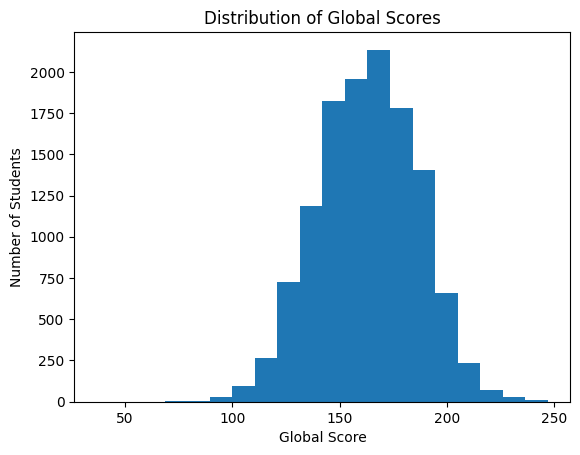

In [14]:
#plot the distribution
plt.hist(df['G_SC'], bins=20)
plt.xlabel('Global Score')
plt.ylabel('Number of Students')
plt.title('Distribution of Global Scores')
plt.show()

6. Parental Education and Academic Performance

In [15]:
# Remove possible extra spaces in education category labels
df['EDU_FATHER'] = df['EDU_FATHER'].str.strip()
df['EDU_MOTHER'] = df['EDU_MOTHER'].str.strip()

# Compare Global Score across father's and mother's education levels
father_edu = (
    df.groupby('EDU_FATHER')['G_SC']
      .agg(['count', 'mean', 'median'])
)

mother_edu = (
    df.groupby('EDU_MOTHER')['G_SC']
      .agg(['count', 'mean', 'median'])
)

father_edu

,count,mean,median
EDU_FATHER,,,
0,391,155.076726,155.0
Complete Secundary,2843,158.785790,159.0
Complete primary,824,155.195388,155.0
Complete professional education,3016,167.765915,169.0
Complete technique or technology,1194,164.033501,164.0
Incomplete Professional Education,425,166.917647,168.0
Incomplete Secundary,1091,156.535289,157.0
Incomplete primary,735,155.729252,156.0
Incomplete technical or technological,277,162.101083,162.0


In [16]:
#order the eductaion level
education_level_order = [
    'Not sure',
    '0',
    'Ninguno',
    'Incomplete primary',
    'Complete primary',
    'Incomplete Secundary',
    'Complete Secundary',
    'Incomplete technical or technological',
    'Complete technique or technology',
    'Incomplete Professional Education',
    'Complete professional education',
    'Postgraduate education'
]

father_edu = father_edu.reindex(education_level_order)
mother_edu = mother_edu.reindex(education_level_order)

father_edu

,count,mean,median
EDU_FATHER,,,
Not sure,407,160.294840,159.0
0,391,155.076726,155.0
Ninguno,123,156.634146,159.0
Incomplete primary,735,155.729252,156.0
Complete primary,824,155.195388,155.0
Incomplete Secundary,1091,156.535289,157.0
Complete Secundary,2843,158.785790,159.0
Incomplete technical or technological,277,162.101083,162.0
Complete technique or technology,1194,164.033501,164.0


In [17]:
mother_edu

,count,mean,median
EDU_MOTHER,,,
Not sure,179,159.407821,159.0
0,388,154.930412,155.0
Ninguno,34,149.705882,152.5
Incomplete primary,541,154.853974,155.0
Complete primary,713,155.336606,155.0
Incomplete Secundary,1056,155.672348,156.0
Complete Secundary,3106,158.470702,159.0
Incomplete technical or technological,341,161.879765,164.0
Complete technique or technology,1495,163.242140,163.0


In [18]:
# Define valid parental education levels from lowest to highest
# drop "0" values and "Not sure" values
valid_education_order = [
    'Ninguno',
    'Incomplete primary',
    'Complete primary',
    'Incomplete Secundary',
    'Complete Secundary',
    'Incomplete technical or technological',
    'Complete technique or technology',
    'Incomplete Professional Education',
    'Complete professional education',
    'Postgraduate education'
]

father_edu_valid = father_edu.reindex(valid_education_order)
mother_edu_valid = mother_edu.reindex(valid_education_order)

father_edu_valid

,count,mean,median
EDU_FATHER,,,
Ninguno,123,156.634146,159.0
Incomplete primary,735,155.729252,156.0
Complete primary,824,155.195388,155.0
Incomplete Secundary,1091,156.535289,157.0
Complete Secundary,2843,158.785790,159.0
Incomplete technical or technological,277,162.101083,162.0
Complete technique or technology,1194,164.033501,164.0
Incomplete Professional Education,425,166.917647,168.0
Complete professional education,3016,167.765915,169.0


In [19]:
mother_edu_valid

,count,mean,median
EDU_MOTHER,,,
Ninguno,34,149.705882,152.5
Incomplete primary,541,154.853974,155.0
Complete primary,713,155.336606,155.0
Incomplete Secundary,1056,155.672348,156.0
Complete Secundary,3106,158.470702,159.0
Incomplete technical or technological,341,161.879765,164.0
Complete technique or technology,1495,163.242140,163.0
Incomplete Professional Education,502,166.685259,168.0
Complete professional education,3059,168.845374,170.0


In [20]:
# Calculate the difference in mean Global Score between
# postgraduate and complete primary parental education

father_gap = (
    father_edu_valid.loc['Postgraduate education', 'mean']
    - father_edu_valid.loc['Ninguno', 'mean']
)

mother_gap = (
    mother_edu_valid.loc['Postgraduate education', 'mean']
    - mother_edu_valid.loc['Ninguno', 'mean']
)

print("Father education gap:", round(father_gap, 1))
print("Mother education gap:", round(mother_gap, 1))

Father education gap: 20.4
Mother education gap: 25.9


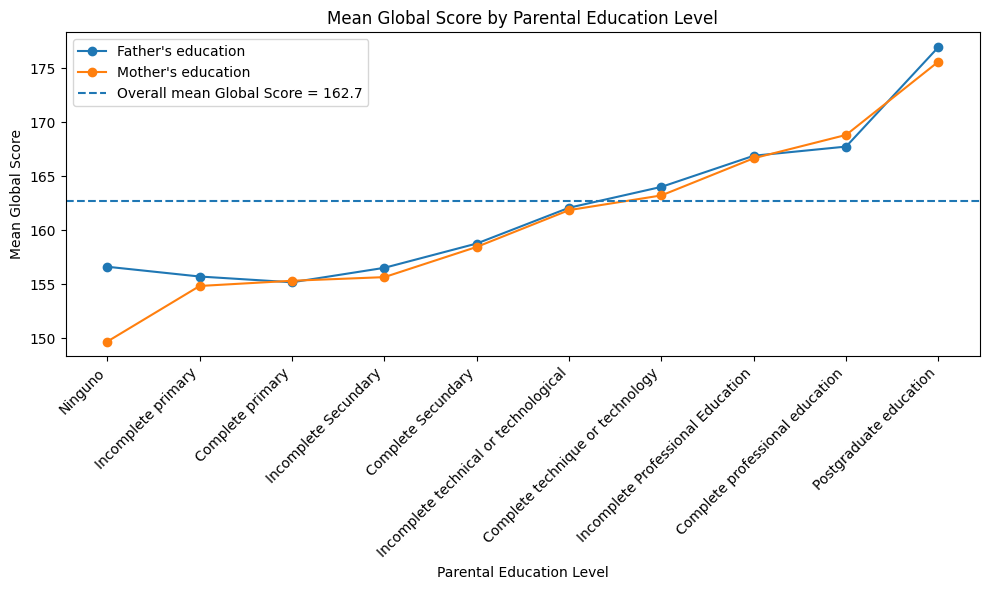

In [21]:
# Compare mean Global Score across parental education levels

plt.figure(figsize=(10, 6))

plt.plot(
    valid_education_order,
    father_edu_valid['mean'],
    marker='o',
    label="Father's education"
)

plt.plot(
    valid_education_order,
    mother_edu_valid['mean'],
    marker='o',
    label="Mother's education"
)

# Add overall mean as a reference line
overall_mean = df['G_SC'].mean()
plt.axhline(
    y=overall_mean,
    linestyle='--',
    linewidth=1.5,
    label=f'Overall mean Global Score = {overall_mean:.1f}'
)

plt.xlabel('Parental Education Level')
plt.ylabel('Mean Global Score')
plt.title('Mean Global Score by Parental Education Level')

plt.xticks(rotation=45, ha='right')
plt.legend()
plt.tight_layout()
plt.show()

7. Socioeconomic Stratum and Academic Performance

In [22]:
# Compare Global Score across socioeconomic strata
stratum_summary = (
    df.groupby('STRATUM')['G_SC']
      .agg(['count', 'mean', 'median'])
)

stratum_summary

,count,mean,median
STRATUM,,,
0,14,154.000000,152.5
Stratum 1,1709,152.352838,152.0
Stratum 2,4029,158.199305,158.0
Stratum 3,4045,163.815328,164.0
Stratum 4,1578,172.002535,174.0
Stratum 5,633,177.387046,179.0
Stratum 6,403,181.511166,184.0


In [23]:
# Calculate the difference in mean Global Score between the highest and lowest socioeconomic strata
stratum_gap = (
    stratum_summary.loc['Stratum 6', 'mean']
    - stratum_summary.loc['Stratum 1', 'mean']
)

print("Stratum 6 - Stratum 1 mean score gap:",
      round(stratum_gap, 2))


Stratum 6 - Stratum 1 mean score gap: 29.16


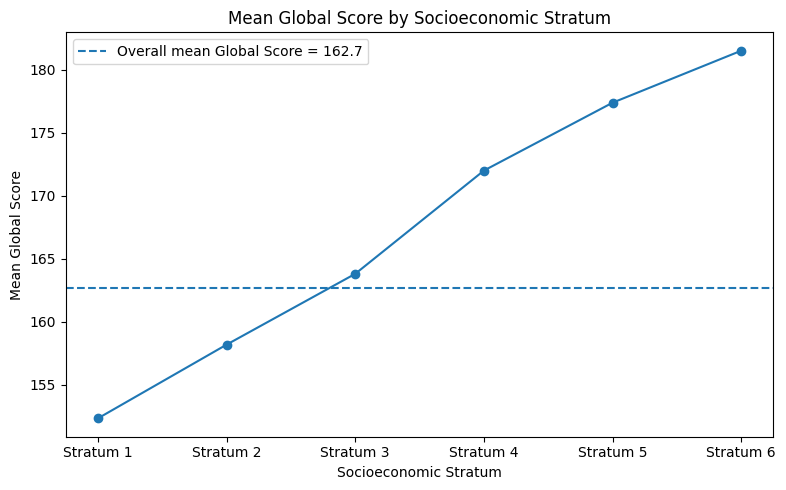

In [24]:
# Exclude the unclear "0" category
stratum_valid = stratum_summary.loc[
    ['Stratum 1', 'Stratum 2', 'Stratum 3',
     'Stratum 4', 'Stratum 5', 'Stratum 6']
]

# Plot mean Global Score across socioeconomic strata
plt.figure(figsize=(8, 5))

plt.plot(
    stratum_valid.index,
    stratum_valid['mean'],
    marker='o'
)
# Add overall mean as a reference line
plt.axhline(
    y=overall_mean,
    linestyle='--',
    linewidth=1.5,
    label=f'Overall mean Global Score = {overall_mean:.1f}'
)

plt.xlabel('Socioeconomic Stratum')
plt.ylabel('Mean Global Score')
plt.title('Mean Global Score by Socioeconomic Stratum')
plt.legend()
plt.tight_layout()
plt.show()

8. Gender and Academic Performance

In [25]:
# Compare Global Score by gender
gender_summary = (
    df.groupby('GENDER')['G_SC']
      .agg(['count', 'mean', 'median'])
)

gender_summary

,count,mean,median
GENDER,,,
F,5043,161.278207,162.0
M,7368,163.690825,164.0


In [26]:
# Calculate the difference in mean Global Score between genders
gender_gap = (
    gender_summary.loc['M', 'mean']
    - gender_summary.loc['F', 'mean']
)

print("Mean Global Score difference between Male students and Female students (M - F):",
      round(gender_gap, 2))

Mean Global Score difference between Male students and Female students (M - F): 2.41


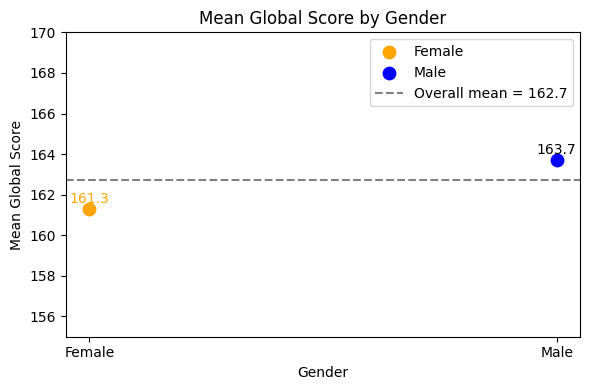

In [27]:
# Plot mean Global Score by gender
overall_mean = df['G_SC'].mean()

female_mean = gender_summary.loc['F', 'mean']
male_mean = gender_summary.loc['M', 'mean']

plt.figure(figsize=(6, 4))

# Plot the two points
plt.scatter(0, female_mean, color='orange', s=80, label='Female')
plt.scatter(1, male_mean, color='blue', s=80, label='Male')

# Add overall mean reference line
plt.axhline(
    y=overall_mean,
    linestyle='--',
    color='gray',
    label=f'Overall mean = {overall_mean:.1f}'
)

# Add labels for the two points
plt.text(0, female_mean + 0.3, f'{female_mean:.1f}', ha='center', color='orange')
plt.text(1, male_mean + 0.3, f'{male_mean:.1f}', ha='center')

# Set x-axis labels
plt.xticks([0, 1], ['Female', 'Male'])

# Widen the y-axis range
plt.ylim(155, 170)

plt.xlabel('Gender')
plt.ylabel('Mean Global Score')
plt.title('Mean Global Score by Gender')

plt.legend()
plt.tight_layout()
plt.show()

since this is a more explicit and simpler variable, I won't put the graph into the report.Just a summary of the result will be enough to illustrate the gender gap.

9. Prior Academic Preparation and Later Academic Performance


In [28]:
# Variables from high school (prior academic related variables)
# MAT_S11  Mathematics
# CR_S11   Critical Reading
# CC_S11   Citizen Competencies
# BIO_S11  Biology
# ENG_S11  English"

s11_scores = [
    'MAT_S11',
    'CR_S11',
    'CC_S11',
    'BIO_S11',
    'ENG_S11'
]
prior_correlations = (
    df[s11_scores + ['G_SC']]
      .corr()['G_SC']
      .drop('G_SC')
      .sort_values(ascending=False)
)

prior_correlations

,G_SC
BIO_S11,0.666635
ENG_S11,0.662169
CR_S11,0.653572
MAT_S11,0.643838
CC_S11,0.634900


In [29]:
# Create an overall measure of prior academic preparation
df['S11_average'] = df[
    ['MAT_S11', 'CR_S11', 'CC_S11', 'BIO_S11', 'ENG_S11']
].mean(axis=1)

# Correlation between average Saber 11 performance and Global Score
prior_overall_corr = df['S11_average'].corr(df['G_SC'])

print(
    "Correlation between average Saber 11 score and Global Score:",
    round(prior_overall_corr, 3)
)

Correlation between average Saber 11 score and Global Score: 0.778


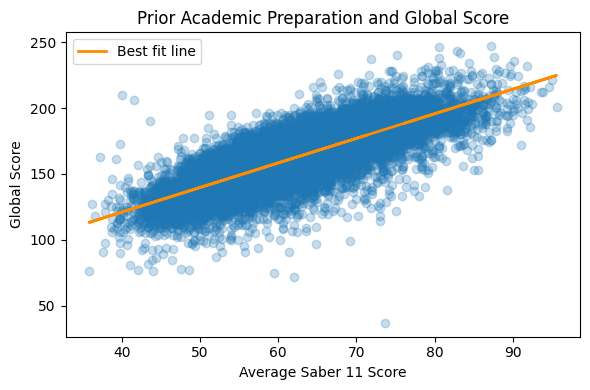

In [30]:
# Visualize the relationship between overall prior academic preparation
# and end-of-program Global Score
x = df['S11_average']
y = df['G_SC']

# Calculate the best-fit line
slope, intercept = np.polyfit(x, y, 1)

plt.figure(figsize=(6, 4))

plt.scatter(
    x,
    y,
    alpha=0.25
)

plt.plot(
    x,
    slope * x + intercept,
    color='darkorange',
    linewidth=2,
    label='Best fit line'
)

plt.xlabel('Average Saber 11 Score')
plt.ylabel('Global Score')
plt.title('Prior Academic Preparation and Global Score')
plt.legend()

plt.tight_layout()
plt.show()